# Phase 4 — Detailed Modelling, Validation, and One-Time Test Evaluation

Model, features, hyperparameters, and threshold are chosen without test access. The final section opens the governed test partition once.

## 1. Imports and processed data

In [1]:
from pathlib import Path
import json,joblib,warnings,numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from IPython.display import display,Markdown
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold,cross_validate,cross_val_predict
from sklearn.metrics import *
from sklearn.inspection import permutation_importance
root=Path.cwd()
if not (root/'data/governed/train_engineered.csv').exists(): root=root.parent
train=pd.read_csv(root/'data/governed/train_engineered.csv'); test=pd.read_csv(root/'data/governed/validation_engineered.csv'); TARGET='Machine failure'; Xtr=train.drop(columns=TARGET); ytr=train[TARGET]; Xte=test.drop(columns=TARGET); yte=test[TARGET]; print(train.shape,test.shape)

(7000, 10) (1500, 10)


## 2. Split integrity and prevalence

In [2]:
display(pd.DataFrame({'rows':[len(train),len(test)],'failures':[ytr.sum(),yte.sum()],'rate':[ytr.mean(),yte.mean()]},index=['train','test'])); assert Xtr.columns.tolist()==Xte.columns.tolist()

,rows,failures,rate
train,7000,237,0.033857
test,1500,51,0.034000


## 3. Preprocessor and candidate registry

In [3]:
cat=['Type']; num=[c for c in Xtr if c!='Type']; pre=ColumnTransformer([('n',StandardScaler(),num),('c',OneHotEncoder(handle_unknown='ignore'),cat)])
models={'Dummy':DummyClassifier(strategy='prior'),'Logistic regression':LogisticRegression(class_weight='balanced',max_iter=2000,random_state=42),'Random forest':RandomForestClassifier(n_estimators=500,min_samples_leaf=2,class_weight='balanced_subsample',random_state=42,n_jobs=1)}
pipes={k:Pipeline([('pre',pre),('model',v)]) for k,v in models.items()}; print(models)

{'Dummy': DummyClassifier(), 'Logistic regression': LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42), 'Random forest': RandomForestClassifier(class_weight='balanced_subsample', min_samples_leaf=2,
                       n_estimators=500, n_jobs=1, random_state=42)}


## 4. Metric strategy

In [4]:
print('Primary: PR-AUC. Secondary: ROC-AUC, recall, precision, F1, balanced accuracy. Accuracy alone is rejected because prevalence is low.')

Primary: PR-AUC. Secondary: ROC-AUC, recall, precision, F1, balanced accuracy. Accuracy alone is rejected because prevalence is low.


## 5. Five-fold stratified cross-validation

In [5]:
cv=StratifiedKFold(5,shuffle=True,random_state=42); scoring={'pr_auc':'average_precision','roc_auc':'roc_auc','recall':'recall','precision':make_scorer(precision_score,zero_division=0),'f1':'f1','balanced_accuracy':'balanced_accuracy'}; rows=[]
for name,p in pipes.items():
 s=cross_validate(p,Xtr,ytr,cv=cv,scoring=scoring,n_jobs=1); row={'model':name}; row.update({f'{m}_mean':s[f"test_{m}"].mean() for m in scoring}); row.update({f'{m}_std':s[f"test_{m}"].std(ddof=1) for m in scoring}); rows.append(row)
cvres=pd.DataFrame(rows).sort_values('pr_auc_mean',ascending=False); display(cvres)

,model,pr_auc_mean,roc_auc_mean,recall_mean,precision_mean,f1_mean,balanced_accuracy_mean,pr_auc_std,roc_auc_std,recall_std,precision_std,f1_std,balanced_accuracy_std
2,Random forest,0.888456,0.980086,0.789184,0.951304,0.85868,0.893853,0.046816,0.011079,0.105895,0.024869,0.059719,0.052639
1,Logistic regression,0.448316,0.925837,0.827394,0.161910,0.27070,0.838731,0.048603,0.012635,0.064121,0.004224,0.008599,0.028235
0,Dummy,0.033857,0.500000,0.000000,0.000000,0.00000,0.500000,0.000391,0.000000,0.000000,0.000000,0.000000,0.000000


## 6. Cross-validation visualization

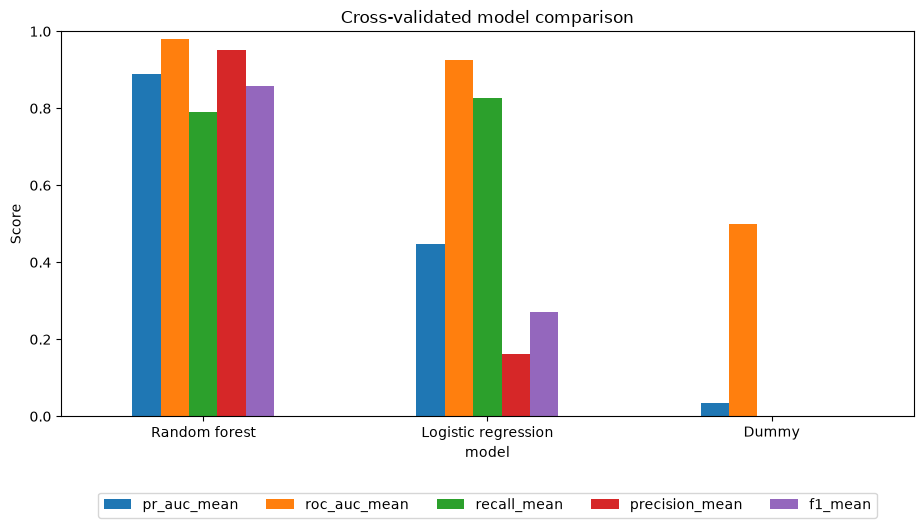

In [6]:
cols=['pr_auc_mean','roc_auc_mean','recall_mean','precision_mean','f1_mean']; cvres.set_index('model')[cols].plot.bar(figsize=(11,5)); plt.ylim(0,1); plt.ylabel('Score'); plt.title('Cross-validated model comparison'); plt.xticks(rotation=0); plt.legend(bbox_to_anchor=(.5,-.18),loc='upper center',ncol=5); plt.show()

## 7. Model selection

In [7]:
winner=cvres.iloc[0].model; selected=pipes[winner]; print('Selected by mean PR-AUC:',winner)

Selected by mean PR-AUC: Random forest


## 8. Out-of-fold probability diagnostics

OOF PR-AUC 0.8867678117642881 OOF ROC-AUC 0.979600781367468


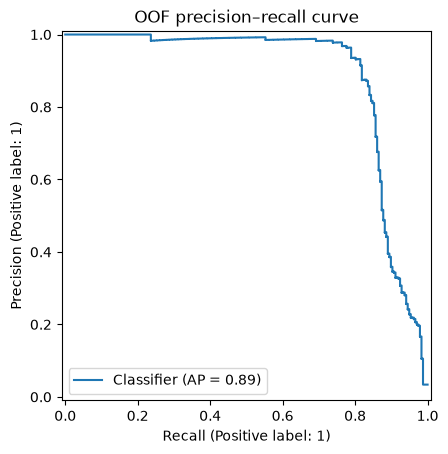

In [8]:
oof=cross_val_predict(selected,Xtr,ytr,cv=cv,method='predict_proba',n_jobs=1)[:,1]; print('OOF PR-AUC',average_precision_score(ytr,oof),'OOF ROC-AUC',roc_auc_score(ytr,oof)); PrecisionRecallDisplay.from_predictions(ytr,oof); plt.title('OOF precision–recall curve'); plt.show()

## 9. Training-only threshold selection

In [9]:
p,r,t=precision_recall_curve(ytr,oof); tab=pd.DataFrame({'threshold':t,'precision':p[:-1],'recall':r[:-1]}); eligible=tab[tab.recall>=.80]; threshold=float(eligible.sort_values(['precision','threshold'],ascending=[False,False]).iloc[0].threshold); display(tab.iloc[(tab.threshold-threshold).abs().argsort()[:10]]); print(threshold)

,threshold,precision,recall
2574,0.483308,0.935961,0.801688
2575,0.484724,0.935644,0.797468
2576,0.487144,0.935323,0.793249
2577,0.492445,0.935000,0.789030
2578,0.494090,0.939698,0.789030
2573,0.468613,0.931373,0.801688
2579,0.499550,0.944444,0.789030
2580,0.501945,0.949239,0.789030
2572,0.464351,0.931707,0.805907
2571,0.463540,0.932039,0.810127


0.48330825410539285


## 10. Fit selected pipeline

In [10]:
final=selected.fit(Xtr,ytr); prob=final.predict_proba(Xte)[:,1]; pred50=(prob>=.5).astype(int); pred=(prob>=threshold).astype(int)

## 11. Locked validation metrics

In [11]:
def metrics(label,pred): return {'point':label,'threshold':.5 if label=='default' else threshold,'pr_auc':average_precision_score(yte,prob),'roc_auc':roc_auc_score(yte,prob),'precision':precision_score(yte,pred),'recall':recall_score(yte,pred),'f1':f1_score(yte,pred),'balanced_accuracy':balanced_accuracy_score(yte,pred)}
test_metrics=pd.DataFrame([metrics('default',pred50),metrics('selected',pred)]); display(test_metrics)

,point,threshold,pr_auc,roc_auc,precision,recall,f1,balanced_accuracy
0,default,0.500000,0.831909,0.953315,0.947368,0.705882,0.808989,0.852251
1,selected,0.483308,0.831909,0.953315,0.948718,0.725490,0.822222,0.862055


## 12. Classification report

In [12]:
print(classification_report(yte,pred,target_names=['No failure','Failure'],digits=4))

              precision    recall  f1-score   support

  No failure     0.9904    0.9986    0.9945      1449
     Failure     0.9487    0.7255    0.8222        51

    accuracy                         0.9893      1500
   macro avg     0.9696    0.8621    0.9084      1500
weighted avg     0.9890    0.9893    0.9886      1500



## 13. PR, ROC, and confusion visuals

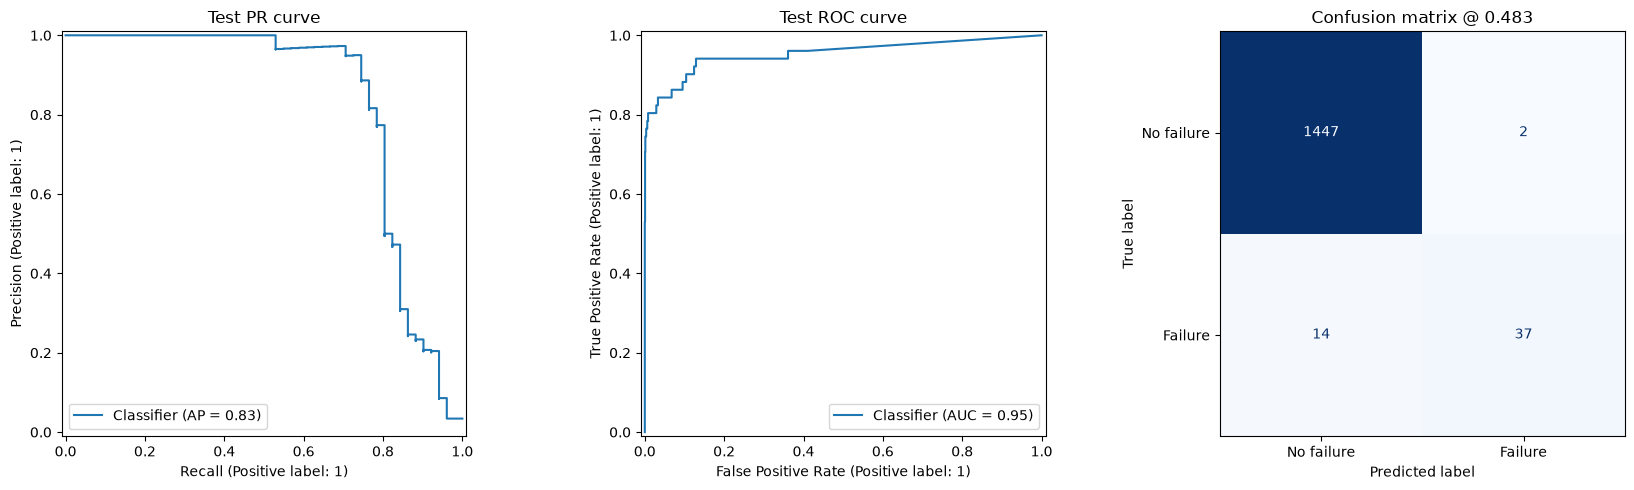

In [13]:
fig,ax=plt.subplots(1,3,figsize=(17,5)); PrecisionRecallDisplay.from_predictions(yte,prob,ax=ax[0]); RocCurveDisplay.from_predictions(yte,prob,ax=ax[1]); ConfusionMatrixDisplay.from_predictions(yte,pred,display_labels=['No failure','Failure'],cmap='Blues',colorbar=False,ax=ax[2]); ax[0].set_title('Test PR curve'); ax[1].set_title('Test ROC curve'); ax[2].set_title(f'Confusion matrix @ {threshold:.3f}'); plt.tight_layout(); plt.show()

## 14. Threshold trade-off table

,threshold,precision,recall,flagged
0,0.10,0.493976,0.803922,83
1,0.15,0.630769,0.803922,65
2,0.20,0.769231,0.784314,52
3,0.25,0.812500,0.764706,48
4,0.30,0.886364,0.764706,44
5,0.35,0.883721,0.745098,43
6,0.40,0.948718,0.725490,39
7,0.45,0.948718,0.725490,39
8,0.50,0.947368,0.705882,38
9,0.55,0.971429,0.666667,35


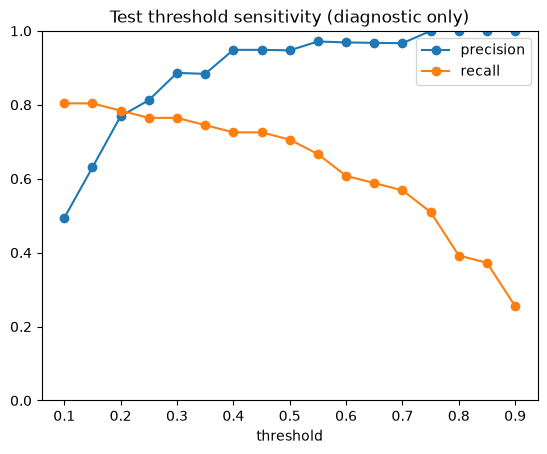

In [14]:
grid=np.linspace(.1,.9,17); trade=pd.DataFrame([{'threshold':x,'precision':precision_score(yte,prob>=x,zero_division=0),'recall':recall_score(yte,prob>=x),'flagged':int((prob>=x).sum())} for x in grid]); display(trade); trade.plot(x='threshold',y=['precision','recall'],marker='o'); plt.ylim(0,1); plt.title('Test threshold sensitivity (diagnostic only)'); plt.show()

## 15. Product-type subgroup performance

In [15]:
diag=Xte[['Type']].copy(); diag['actual']=yte.values; diag['predicted']=pred; diag['probability']=prob; rows=[]
for typ,g in diag.groupby('Type'): rows.append({'Type':typ,'rows':len(g),'failures':g.actual.sum(),'precision':precision_score(g.actual,g.predicted,zero_division=0),'recall':recall_score(g.actual,g.predicted,zero_division=0),'mean_probability':g.probability.mean()})
display(pd.DataFrame(rows))

,Type,rows,failures,precision,recall,mean_probability
0,H,154,5,1.000000,0.600000,0.024477
1,L,878,38,0.966667,0.763158,0.037140
2,M,468,8,0.833333,0.625000,0.021924


## 16. False-negative review

In [16]:
errors=Xte.copy(); errors['actual']=yte.values; errors['predicted']=pred; errors['probability']=prob; fn=errors[(errors.actual==1)&(errors.predicted==0)].sort_values('probability',ascending=False); print('False negatives',len(fn)); display(fn.head(15))

False negatives 14


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperature difference [K],Mechanical power [W],Torque × tool wear,actual,predicted,probability
1246,H,300.5,309.9,1397,45.9,210,9.4,6714.871554,9639.0,1,0,0.398960
366,L,302.7,312.4,1477,46.3,251,9.7,7161.270926,11621.3,1,0,0.348428
299,L,301.7,310.9,1405,46.4,207,9.2,6826.890276,9604.8,1,0,0.244971
753,M,300.0,311.4,1692,29.0,216,11.4,5138.388944,6264.0,1,0,0.191765
1446,L,300.5,311.8,1524,38.9,214,11.3,6208.164075,8324.6,1,0,0.095440
1468,L,298.6,309.8,2271,16.2,218,11.2,3852.660735,3531.6,1,0,0.088611
395,L,298.2,307.6,1511,31.0,209,9.4,4905.178050,6479.0,1,0,0.036703
1342,L,302.7,310.5,1446,40.9,211,7.8,6193.272925,8629.9,1,0,0.023075
108,H,296.9,307.8,1549,35.8,206,10.9,5807.150244,7374.8,1,0,0.019477
1324,L,297.8,308.9,1871,25.6,200,11.1,5015.824943,5120.0,1,0,0.013621


## 17. False-positive review

In [17]:
fp=errors[(errors.actual==0)&(errors.predicted==1)].sort_values('probability',ascending=False); print('False positives',len(fp)); display(fp.head(15))

False positives 2


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperature difference [K],Mechanical power [W],Torque × tool wear,actual,predicted,probability
80,L,302.2,310.8,1340,47.8,54,8.6,6707.509755,2581.2,0,1,0.744486
76,M,302.4,311.2,1330,58.6,201,8.8,8161.648275,11778.6,0,1,0.508979


## 18. Permutation importance

,feature,mean,std
3,Rotational speed [rpm],0.261606,0.032903
6,Temperature difference [K],0.195177,0.024051
8,Torque × tool wear,0.116885,0.006687
7,Mechanical power [W],0.107115,0.015890
5,Tool wear [min],0.067159,0.009978
0,Type,0.024620,0.012009
4,Torque [Nm],0.022792,0.014141
2,Process temperature [K],0.004247,0.004906
1,Air temperature [K],0.001681,0.008203


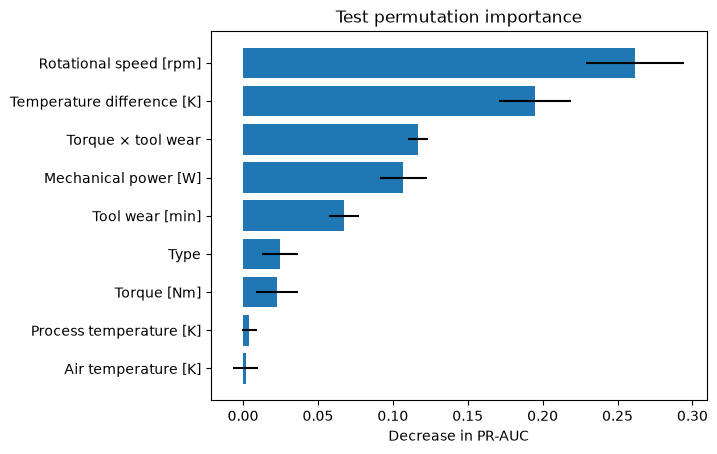

In [18]:
pi=permutation_importance(final,Xte,yte,scoring='average_precision',n_repeats=15,random_state=42,n_jobs=1); imp=pd.DataFrame({'feature':Xte.columns,'mean':pi.importances_mean,'std':pi.importances_std}).sort_values('mean',ascending=False); display(imp); z=imp.sort_values('mean'); plt.barh(z.feature,z['mean'],xerr=z['std']); plt.title('Test permutation importance'); plt.xlabel('Decrease in PR-AUC'); plt.show()

## 19. Prediction-confidence distribution

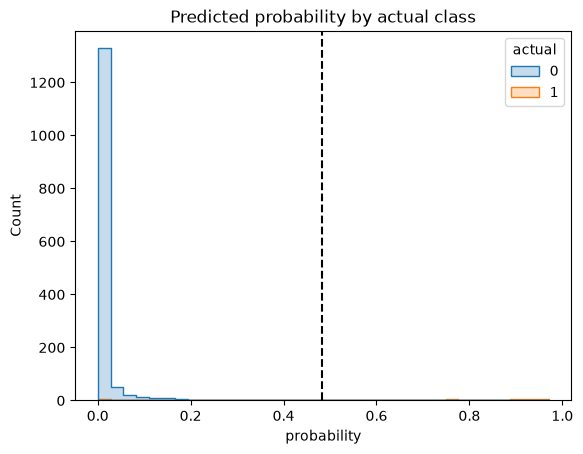

In [19]:
sns.histplot(data=errors,x='probability',hue='actual',bins=35,element='step',common_norm=False); plt.axvline(threshold,color='black',ls='--'); plt.title('Predicted probability by actual class'); plt.show()

## 20. Save expanded workflow artifacts

In [20]:
models=root/'models'; reports=root/'reports'; models.mkdir(exist_ok=True); reports.mkdir(exist_ok=True); joblib.dump(final,models/'detailed_predictive_maintenance_pipeline.joblib'); cvres.to_csv(reports/'detailed_model_cross_validation.csv',index=False); test_metrics.to_csv(reports/'detailed_test_metrics.csv',index=False); imp.to_csv(reports/'detailed_permutation_importance.csv',index=False); print('saved')

saved


## 21. Reproducibility metadata

In [21]:
meta={'model':winner,'threshold':threshold,'random_state':42,'cv_folds':5,'primary_metric':'average_precision','features':Xtr.columns.tolist(),'synthetic_data':True}; (models/'detailed_model_metadata.json').write_text(json.dumps(meta,indent=2)); display(meta)

{'model': 'Random forest',
 'threshold': 0.48330825410539285,
 'random_state': 42,
 'cv_folds': 5,
 'primary_metric': 'average_precision',
 'features': ['Type',
  'Air temperature [K]',
  'Process temperature [K]',
  'Rotational speed [rpm]',
  'Torque [Nm]',
  'Tool wear [min]',
  'Temperature difference [K]',
  'Mechanical power [W]',
  'Torque × tool wear'],
 'synthetic_data': True}

## 22. Final benchmark conclusion

In [22]:
m=test_metrics[test_metrics.point=='selected'].iloc[0]; display(Markdown(f'''- Selected model: **{winner}**
- Test PR-AUC: **{m.pr_auc:.3f}**; ROC-AUC: **{m.roc_auc:.3f}**
- At threshold **{threshold:.3f}**: precision **{m.precision:.3f}**, recall **{m.recall:.3f}**, F1 **{m.f1:.3f}**
- Shareable as a synthetic benchmark with caveats; not deployment-ready without chronological equipment-level validation and operational cost approval.'''))

- Selected model: **Random forest**
- Test PR-AUC: **0.832**; ROC-AUC: **0.953**
- At threshold **0.483**: precision **0.949**, recall **0.725**, F1 **0.822**
- Shareable as a synthetic benchmark with caveats; not deployment-ready without chronological equipment-level validation and operational cost approval.

# Frozen strategy and one-time governed test

Everything above used training and validation only. The selected feature list, preprocessing, random-forest specification, and threshold are now frozen. This section loads `data/governed/test.csv` for the first and only governed evaluation.

In [23]:
governed_test = pd.read_csv(root / "data" / "governed" / "test.csv")
target_column = TARGET
base_feature_columns = ["Type","Air temperature [K]","Process temperature [K]","Rotational speed [rpm]","Torque [Nm]","Tool wear [min]"]
X_governed_test = governed_test[base_feature_columns].copy()
X_governed_test["Temperature difference [K]"] = X_governed_test["Process temperature [K]"] - X_governed_test["Air temperature [K]"]
X_governed_test["Mechanical power [W]"] = 2*np.pi*X_governed_test["Rotational speed [rpm]"]*X_governed_test["Torque [Nm]"]/60
X_governed_test["Torque × tool wear"] = X_governed_test["Torque [Nm]"]*X_governed_test["Tool wear [min]"]
X_governed_test = X_governed_test[Xtr.columns]
y_governed_test = governed_test[target_column]
print(X_governed_test.shape, y_governed_test.mean())

(1500, 9) 0.034


In [24]:
from sklearn.base import clone
X_development = pd.concat([Xtr, Xte], ignore_index=True)
y_development = pd.concat([ytr, yte], ignore_index=True)
governed_pipeline = clone(selected).fit(X_development, y_development)
governed_probabilities = governed_pipeline.predict_proba(X_governed_test)[:, 1]
governed_predictions = (governed_probabilities >= threshold).astype(int)
governed_metrics = {
    "pr_auc": average_precision_score(y_governed_test, governed_probabilities),
    "roc_auc": roc_auc_score(y_governed_test, governed_probabilities),
    "precision": precision_score(y_governed_test, governed_predictions, zero_division=0),
    "recall": recall_score(y_governed_test, governed_predictions, zero_division=0),
    "f1": f1_score(y_governed_test, governed_predictions, zero_division=0),
    "balanced_accuracy": balanced_accuracy_score(y_governed_test, governed_predictions),
}
display(pd.Series(governed_metrics).to_frame("one_time_test"))
print(classification_report(y_governed_test, governed_predictions, digits=4))

,one_time_test
pr_auc,0.956595
roc_auc,0.984256
precision,0.957447
recall,0.882353
f1,0.918367
balanced_accuracy,0.940486


              precision    recall  f1-score   support

           0     0.9959    0.9986    0.9972      1449
           1     0.9574    0.8824    0.9184        51

    accuracy                         0.9947      1500
   macro avg     0.9767    0.9405    0.9578      1500
weighted avg     0.9946    0.9947    0.9946      1500



In [25]:
joblib.dump(governed_pipeline, root / "models" / "final_governed_pipeline.joblib")
(root / "reports" / "final_governed_test_metrics.json").write_text(json.dumps(governed_metrics, indent=2))
print("Final governed pipeline and one-time test metrics saved.")

Final governed pipeline and one-time test metrics saved.


## Final interpretation

The governed test result is reported without returning to feature engineering, tuning, or threshold selection. It remains a synthetic benchmark rather than external factory validation.